Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded. User 'katia' removed.
Remaining users for LOSO: ['debora' 'wallace' 'jose_carlos']
Starting Nested LOSO CV for 3 users...

--- Processing Fold: Held-out User [debora] ---


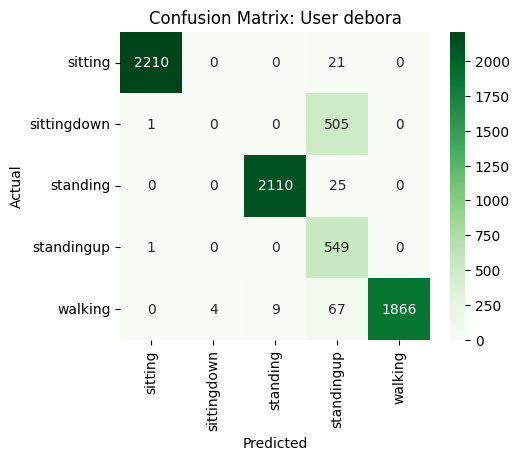

--- Processing Fold: Held-out User [jose_carlos] ---


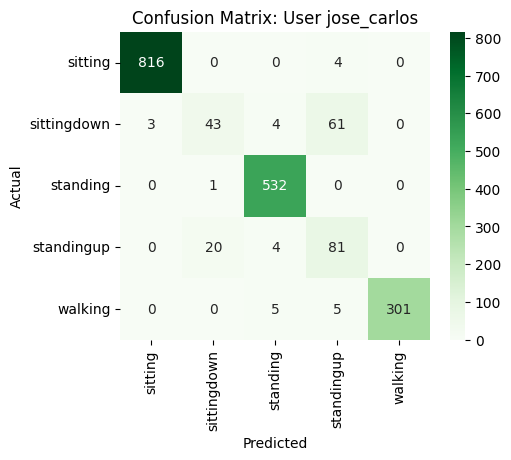

--- Processing Fold: Held-out User [wallace] ---


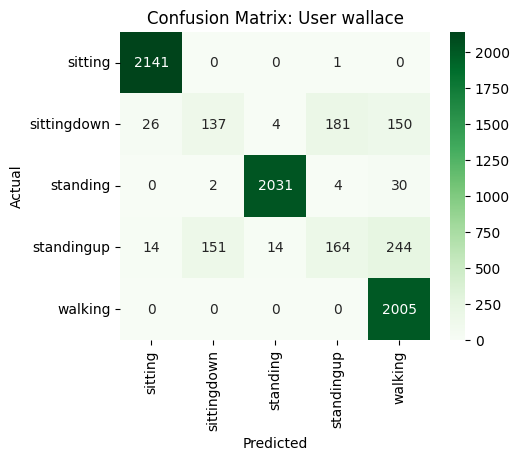

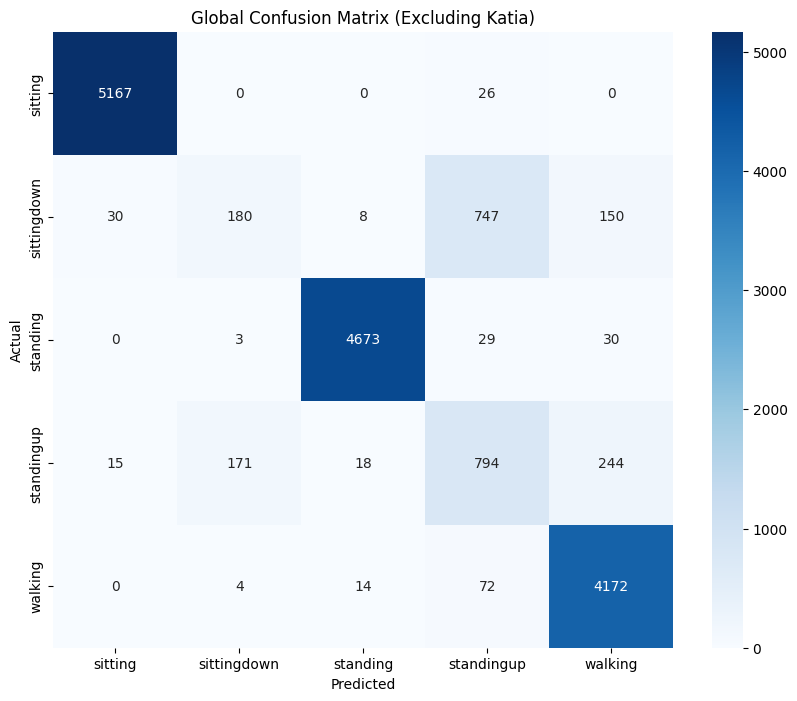

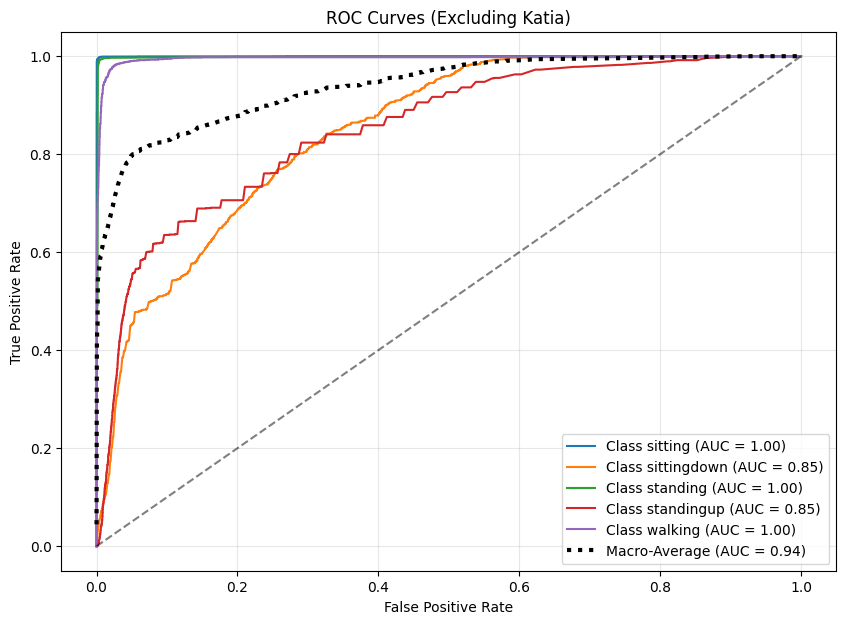

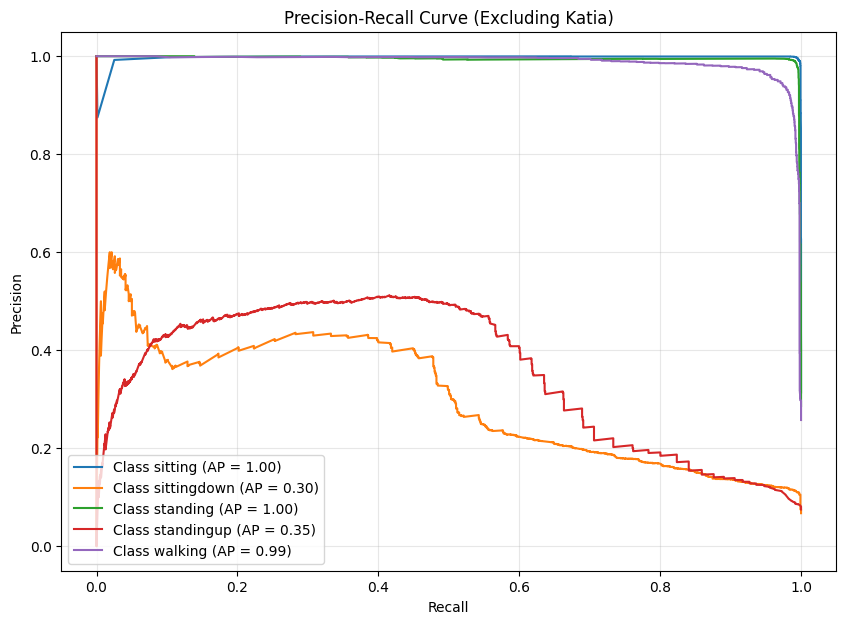


FINAL NESTED LOSO RESULTS (KATIA EXCLUDED)
       User  F1-Score
     debora  0.894987
jose_carlos  0.941217
    wallace  0.870459
--------------------------------------------------
Mean F1-Score: 0.9022
--------------------------------------------------

Global Classification Report:
              precision    recall  f1-score   support

     sitting       0.99      0.99      0.99      5193
 sittingdown       0.50      0.16      0.24      1115
    standing       0.99      0.99      0.99      4735
  standingup       0.48      0.64      0.55      1242
     walking       0.91      0.98      0.94      4262

    accuracy                           0.91     16547
   macro avg       0.77      0.75      0.74     16547
weighted avg       0.90      0.91      0.89     16547



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score, classification_report)
from sklearn.model_selection import RandomizedSearchCV, LeaveOneGroupOut
from sklearn.preprocessing import label_binarize

# 1. Mount Google Drive and Load Data
drive.mount('/content/drive')
dataset_path = '/content/drive/MyDrive/Colab/windowed.csv'

try:
    df = pd.read_csv(dataset_path)

    # --- MODIFICATION: FILTER OUT USER 'katia' ---
    # We remove all rows where the 'user' column is 'katia'
    windowed_df = df[df['user'] != 'katia'].copy()

    # Verify the removal
    remaining_users = windowed_df['user'].unique()
    print(f"Dataset loaded. User 'katia' removed.")
    print(f"Remaining users for LOSO: {remaining_users}")

    X = windowed_df.drop(columns=['class', 'user'])
    y = windowed_df['class']
    groups = windowed_df['user']
    classes = np.unique(y)
    n_classes = len(classes)

except Exception as e:
    print(f"Error loading dataset: {e}")
    windowed_df = None

if windowed_df is not None:
    # 2. Hyperparameter Space Configuration
    param_dist_rf = {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10],
        'max_features': ['sqrt', 'log2'],
        'bootstrap': [True]
    }

    loso = LeaveOneGroupOut()

    # Lists to store global results for aggregation
    all_y_true = []
    all_y_pred = []
    all_y_proba = []
    fold_summaries = []

    print(f"Starting Nested LOSO CV for {len(np.unique(groups))} users...\n")

    # 3. Manual Nested LOSO Loop
    # Now this loop will only iterate through the remaining users
    for train_idx, test_idx in loso.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        held_out_user = groups.iloc[test_idx].unique()[0]

        print(f"--- Processing Fold: Held-out User [{held_out_user}] ---")

        # Inner CV for hyperparameter tuning
        inner_cv = 3
        random_search = RandomizedSearchCV(
            estimator=RandomForestClassifier(random_state=42),
            param_distributions=param_dist_rf,
            n_iter=10,
            cv=inner_cv,
            scoring='f1_weighted',
            n_jobs=-1,
            verbose=0
        )

        random_search.fit(X_train, y_train)
        best_model = random_search.best_estimator_

        # Predictions
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)

        # Calculate F1 for this specific user
        f1 = f1_score(y_test, y_pred, average='weighted')

        # Store data for global analysis
        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
        all_y_proba.extend(y_proba)
        fold_summaries.append({'User': held_out_user, 'F1-Score': f1})

        # Display Individual Confusion Matrix for this user
        cm_user = confusion_matrix(y_test, y_pred, labels=classes)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm_user, annot=True, fmt='d', cmap='Greens',
                    xticklabels=classes, yticklabels=classes)
        plt.title(f'Confusion Matrix: User {held_out_user}')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.show()

    # Convert accumulated lists to arrays
    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)
    all_y_proba = np.array(all_y_proba)

    # Binarize labels for multi-class ROC/PR curves
    y_true_bin = label_binarize(all_y_true, classes=classes)

    # --- FINAL VISUALIZATIONS ---

    # 1. Global Confusion Matrix
    plt.figure(figsize=(10, 8))
    cm_total = confusion_matrix(all_y_true, all_y_pred, labels=classes)
    sns.heatmap(cm_total, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title('Global Confusion Matrix (Excluding Katia)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # 2. ROC Curves
    plt.figure(figsize=(10, 7))
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_y_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], label=f'Class {classes[i]} (AUC = {roc_auc[i]:.2f})')

    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    plt.plot(all_fpr, mean_tpr, label=f'Macro-Average (AUC = {auc(all_fpr, mean_tpr):.2f})',
             color='black', linestyle=':', linewidth=3)

    plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    plt.title('ROC Curves (Excluding Katia)')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

    # 3. Precision-Recall Curves
    plt.figure(figsize=(10, 7))
    for i in range(n_classes):
        precision, recall, _ = precision_recall_curve(y_true_bin[:, i], all_y_proba[:, i])
        avg_p = average_precision_score(y_true_bin[:, i], all_y_proba[:, i])
        plt.plot(recall, precision, label=f'Class {classes[i]} (AP = {avg_p:.2f})')

    plt.title('Precision-Recall Curve (Excluding Katia)')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend(loc='lower left')
    plt.grid(alpha=0.3)
    plt.show()

    # --- FINAL SUMMARY ---
    print("\n" + "="*50)
    print("FINAL NESTED LOSO RESULTS (KATIA EXCLUDED)")
    print("="*50)
    results_df = pd.DataFrame(fold_summaries)
    print(results_df.to_string(index=False))
    print("-" * 50)
    print(f"Mean F1-Score: {results_df['F1-Score'].mean():.4f}")
    print("-" * 50)
    print("\nGlobal Classification Report:")
    print(classification_report(all_y_true, all_y_pred))